# Project 1. Banking: Predicting Term-Deposit Subscription
To run, place the dataset at `./data/bank-additional-full.csv` and install the packages in `requirements.txt`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay)

%matplotlib inline
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
os.makedirs("figures", exist_ok=True)

## 1. Data Loading and Exploration

In [2]:
df = pd.read_csv("./data/bank-additional-full.csv", sep=";")
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [4]:
# Summary of numerical features
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
duration,41188.0,258.29,259.28,0.00,102.00,180.00,319.00,4918.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


### 1.1 Data quality checks
We check for exact duplicate rows, the `unknown` label used for missing categorical values, and the `pdays` placeholder value 999.

In [5]:
print("Exact duplicate rows:", df.duplicated().sum())

unknown_counts = (df == "unknown").sum()
unknown_counts = unknown_counts[unknown_counts > 0]
print("\n'unknown' counts per column:")
print(pd.DataFrame({"count": unknown_counts, "percent": (unknown_counts / len(df) * 100).round(2)}))

print("\nShare of rows with pdays == 999 (never contacted before): "
      f"{(df['pdays'] == 999).mean():.1%}")
print("Rows with default == 'yes':", (df['default'] == 'yes').sum())

Exact duplicate rows: 12

'unknown' counts per column:
           count  percent
job          330     0.80
marital       80     0.19
education   1731     4.20
default     8597    20.87
housing      990     2.40
loan         990     2.40

Share of rows with pdays == 999 (never contacted before): 96.3%
Rows with default == 'yes': 3


**Findings**
- There are 12 exact duplicate rows. They will be removed.
- Six categorical columns contain `unknown`. `default` is the largest at 20.9%.
- `pdays = 999` is a code meaning "not previously contacted" (dataset README), not a real number of days. It covers 96% of rows, so treating it as numeric would distort scale-sensitive models.
- `default = yes` appears only 3 times, so this column carries almost no "yes" information.

### 1.2 Target distribution

     count  percent
y                  
no   36548    88.73
yes   4640    11.27


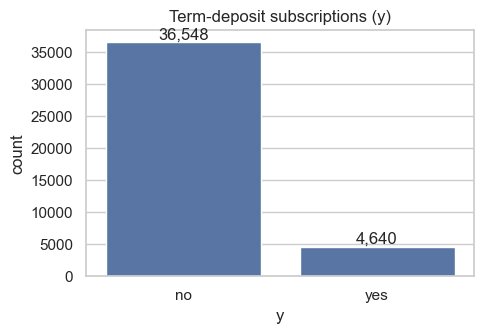

In [6]:
target_counts = df["y"].value_counts()
target_pct = df["y"].value_counts(normalize=True) * 100
print(pd.DataFrame({"count": target_counts, "percent": target_pct.round(2)}))

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x="y", ax=ax, color="#4C72B0")
ax.set_title("Term-deposit subscriptions (y)")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout(); plt.savefig("figures/fig1_target.png", dpi=150); plt.show()

Only 11.3% of calls led to a subscription. This imbalance means accuracy is a poor metric, and we use ROC-AUC, PR-AUC, precision and recall instead.

### 1.3 Which features relate to subscription?

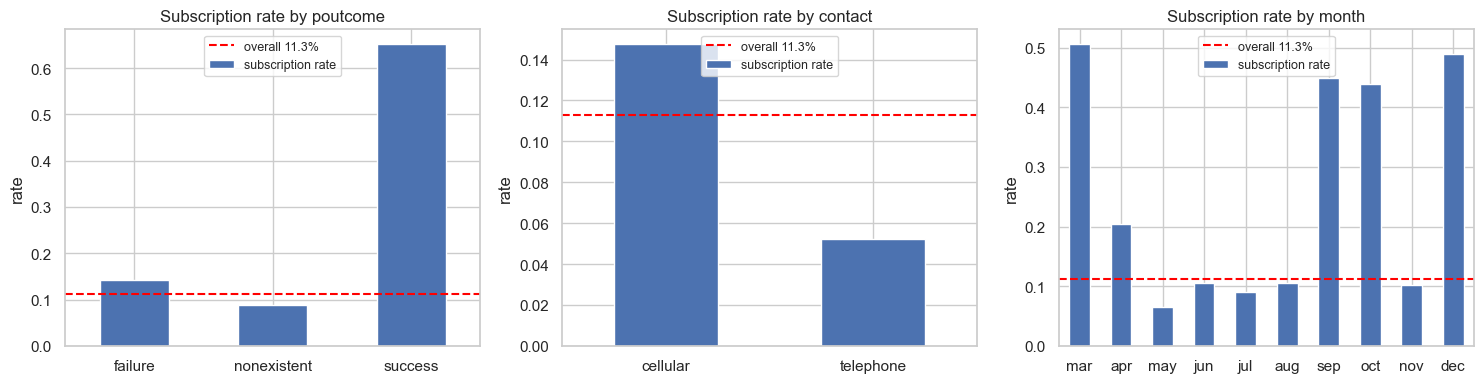

              rate      n
poutcome                 
success      0.651   1373
failure      0.142   4252
nonexistent  0.088  35563 

            rate      n
contact                
cellular   0.147  26144
telephone  0.052  15044 

        rate      n
month              
mar    0.505    546
dec    0.489    182
sep    0.449    570
oct    0.439    718
apr    0.205   2632
aug    0.106   6178
jun    0.105   5318
nov    0.101   4101
jul    0.090   7174
may    0.064  13769 



In [7]:
df["y_bin"] = (df["y"] == "yes").astype(int)
overall = df["y_bin"].mean()

month_order = ["mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, order in zip(axes, ["poutcome", "contact", "month"], [None, None, month_order]):
    rate = df.groupby(col)["y_bin"].mean()
    if order: rate = rate.reindex(order)
    rate.plot(kind="bar", ax=ax, color="#4C72B0", label="subscription rate")
    ax.axhline(overall, color="red", ls="--", label=f"overall {overall:.1%}")
    ax.set_title(f"Subscription rate by {col}"); ax.set_ylabel("rate"); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0); ax.legend(loc="upper center", fontsize=9)
plt.tight_layout(); plt.savefig("figures/fig2_rates.png", dpi=150); plt.show()

for col in ["poutcome", "contact", "month"]:
    print(df.groupby(col)["y_bin"].agg(rate="mean", n="size").round(3).sort_values("rate", ascending=False), "\n")

**Findings**
- **Previous outcome is the strongest single signal.** Customers whose last campaign succeeded subscribe at about 65%, against 9% for those never contacted.
- **Contact type matters.** Cellular converts at about 15% vs telephone at about 5%.
- **Month varies a lot.** March, September, October and December exceed 40%, but these months have few calls (182 to 718). May has the most calls and the lowest rate (6%).

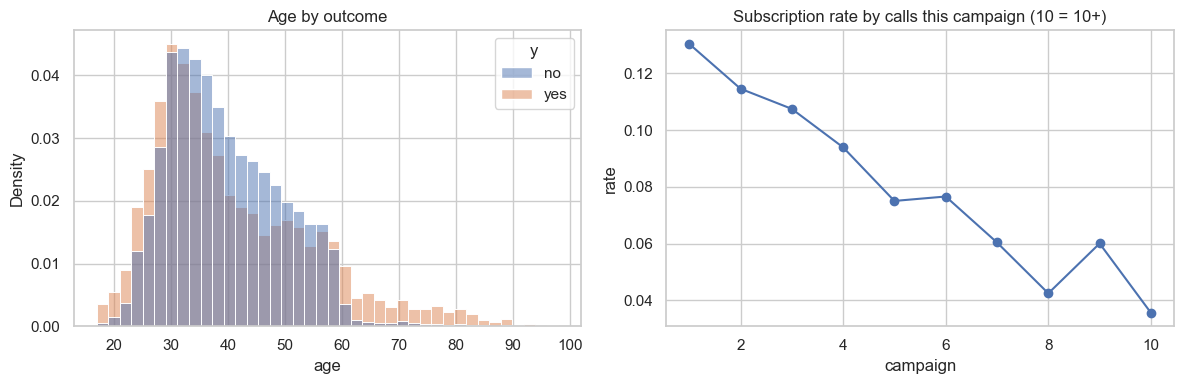

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="age", hue="y", stat="density", common_norm=False, bins=40, ax=axes[0])
axes[0].set_title("Age by outcome")
camp = df.assign(campaign_capped=df["campaign"].clip(upper=10)).groupby("campaign_capped")["y_bin"].mean()
camp.plot(marker="o", ax=axes[1])
axes[1].set_title("Subscription rate by calls this campaign (10 = 10+)")
axes[1].set_xlabel("campaign"); axes[1].set_ylabel("rate")
plt.tight_layout(); plt.savefig("figures/fig3_age_campaign.png", dpi=150); plt.show()

Older (60+) and younger (<25) customers subscribe more often. The subscription rate falls as the number of calls in the current campaign rises, so repeated calling has diminishing returns.

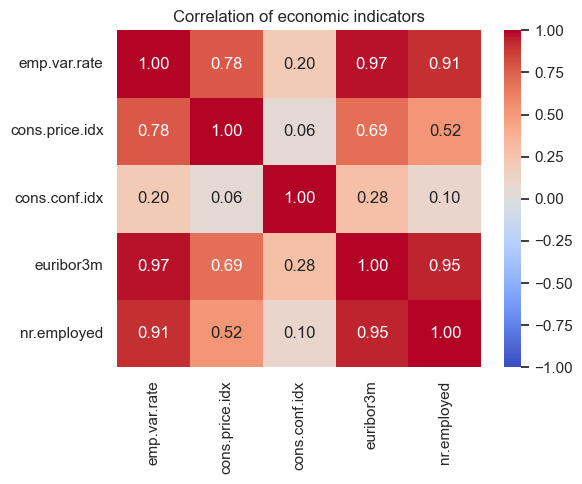

In [9]:
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(df[macro].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation of economic indicators")
plt.tight_layout(); plt.savefig("figures/fig4_macro_corr.png", dpi=150); plt.show()

`euribor3m`, `emp.var.rate` and `nr.employed` correlate at 0.91 to 0.97. This multicollinearity does not hurt prediction, but it makes individual logistic regression coefficients unreliable to interpret. These indicators also change over time, which matters for validation (Section 6).

## 2. Data Preparation and Justification

| Step | Justification |
|---|---|
| Remove 12 duplicate rows | Duplicates add no information and can leak between train and test. |
| Drop `duration` | Call length is only known after the call, and the README says it should be dropped for a realistic model. Keeping it would be target leakage. |
| Replace `pdays` with `prev_contacted` (1 if `pdays != 999`) | 999 is a code, not a number of days. A binary flag keeps the information without distorting scaling. |
| Keep `unknown` as its own category | The README allows this. Missingness may itself be informative (e.g. customers not disclosing default status), and dropping rows would lose 26% of data. |
| One-hot encode categoricals, standardise numericals (LR only) | LR needs comparable scales; tree models do not. Transformations are fitted inside the pipeline so CV folds do not leak. |
| Stratified 80/20 train-test split | Keeps the 11.3% positive rate in both sets. The test set is used once for final evaluation. |

In [10]:
data = df.drop(columns=["y_bin"]).drop_duplicates().reset_index(drop=True)
data = data.drop(columns=["duration"])
data["prev_contacted"] = (data["pdays"] != 999).astype(int)
data = data.drop(columns=["pdays"])

X = data.drop(columns=["y"])
y = (data["y"] == "yes").astype(int)

categorical_cols = X.select_dtypes(exclude="number").columns.tolist()
numerical_cols = X.select_dtypes(include="number").columns.tolist()
print("Rows after cleaning:", len(data))
print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print(f"Train: {X_train.shape}, positive rate {y_train.mean():.3%}")
print(f"Test:  {X_test.shape}, positive rate {y_test.mean():.3%}")

Rows after cleaning: 41176
Numerical columns: ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'prev_contacted']
Categorical columns: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Train: (32940, 19), positive rate 11.266%
Test:  (8236, 19), positive rate 11.268%


In [11]:
def make_preprocessor(scale=True):
    num = StandardScaler() if scale else "passthrough"
    return ColumnTransformer([
        ("num", num, numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols),
    ])

## 3. Majority-Class Baseline
A model that always predicts "no" sets the floor every real model must beat.

In [12]:
baseline = Pipeline([("prep", make_preprocessor()), ("clf", DummyClassifier(strategy="most_frequent"))])
baseline.fit(X_train, y_train)
b_pred = baseline.predict(X_test)
b_prob = baseline.predict_proba(X_test)[:, 1]

baseline_metrics = {
    "Accuracy": accuracy_score(y_test, b_pred),
    "Precision": precision_score(y_test, b_pred, zero_division=0),
    "Recall": recall_score(y_test, b_pred),
    "ROC-AUC": roc_auc_score(y_test, b_prob),
    "PR-AUC": average_precision_score(y_test, b_prob),
}
pd.Series(baseline_metrics).round(3).to_frame("Majority baseline (test)")

,Majority baseline (test)
Accuracy,0.887
Precision,0.000
Recall,0.000
ROC-AUC,0.500
PR-AUC,0.113


The baseline gets 88.7% accuracy but finds **zero** subscribers. Its ROC-AUC is 0.50 and its PR-AUC equals the positive rate (0.113). A useful model must beat these ranking scores, even if its accuracy is lower.

## 4. Model Comparison and Ranking

We compare three common classification approaches.
1. **Logistic Regression.** A simple linear model that is easy to explain.
2. **Random Forest.** Many decision trees averaged together. It can capture non-linear patterns.
3. **Gradient Boosting.** Trees built one after another, each fixing the errors of the last. Often the strongest method on tables of data.

Each model is scored with 5-fold cross-validation on the training data, then once on the test data. We report ROC-AUC and PR-AUC. PR-AUC is the main metric because it focuses on the rare subscribers.

In [13]:
models = {
    "Logistic Regression": Pipeline([("prep", make_preprocessor(scale=True)),
                                     ("clf", LogisticRegression(max_iter=2000))]),
    "Random Forest": Pipeline([("prep", make_preprocessor(scale=False)),
                               ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                                              n_jobs=-1, random_state=RANDOM_STATE))]),
    "Gradient Boosting": Pipeline([("prep", make_preprocessor(scale=False)),
                                   ("clf", HistGradientBoostingClassifier(random_state=RANDOM_STATE))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results, test_prob = [], {}
for name, pipe in models.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["roc_auc", "average_precision"])
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    test_prob[name] = p
    results.append({"Model": name,
                    "CV ROC-AUC": scores["test_roc_auc"].mean(),
                    "CV PR-AUC": scores["test_average_precision"].mean(),
                    "Test ROC-AUC": roc_auc_score(y_test, p),
                    "Test PR-AUC": average_precision_score(y_test, p)})
results.append({"Model": "Majority baseline", "CV ROC-AUC": 0.5, "CV PR-AUC": y_train.mean(),
                "Test ROC-AUC": 0.5, "Test PR-AUC": y_test.mean()})
results = pd.DataFrame(results).set_index("Model")
results.round(3)

,CV ROC-AUC,CV PR-AUC,Test ROC-AUC,Test PR-AUC
Model,,,,
Logistic Regression,0.790,0.451,0.801,0.453
Random Forest,0.795,0.467,0.805,0.484
Gradient Boosting,0.800,0.465,0.812,0.491
Majority baseline,0.500,0.113,0.500,0.113


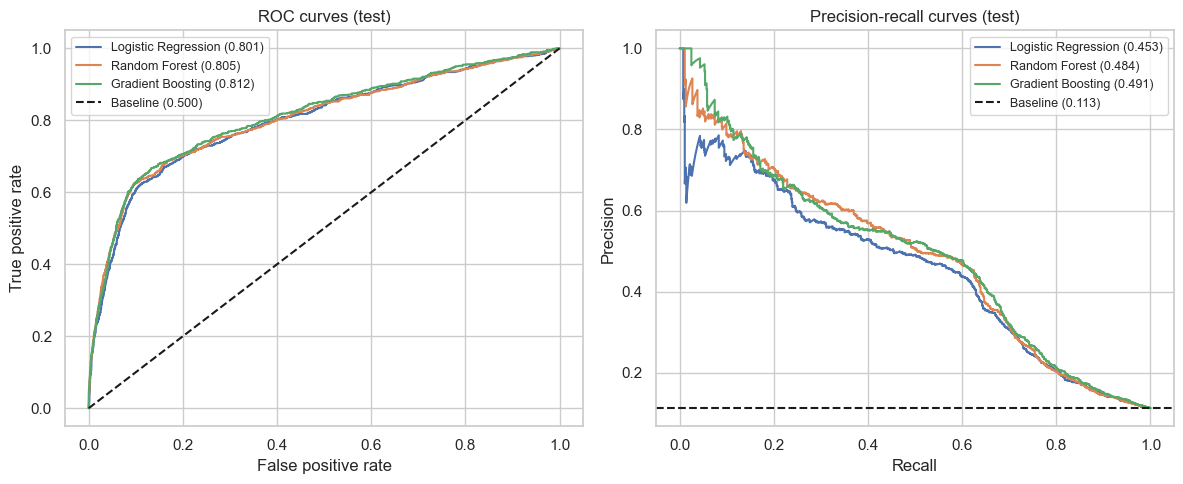

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, p in test_prob.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, label=f"{name} ({average_precision_score(y_test, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="Baseline (0.500)")
axes[1].axhline(y_test.mean(), color="k", ls="--", label=f"Baseline ({y_test.mean():.3f})")
axes[0].set(title="ROC curves (test)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].set(title="Precision-recall curves (test)", xlabel="Recall", ylabel="Precision")
for a in axes: a.legend(fontsize=9)
plt.tight_layout(); plt.savefig("figures/fig5_roc_pr.png", dpi=150); plt.show()

### 4.1 Check on later data
The calls are in date order, and economic conditions change over time. A random split mixes all periods, which may make results look better than they would be on a future campaign. As a simple check, we train on the first 80% of calls and test on the last 20%.

In [15]:
cut = int(len(X) * 0.8)
time_results = []
for name, pipe in models.items():
    m = clone(pipe).fit(X.iloc[:cut], y.iloc[:cut])
    p = m.predict_proba(X.iloc[cut:])[:, 1]
    time_results.append({"Model": name, "ROC-AUC (later data)": roc_auc_score(y.iloc[cut:], p)})
pd.DataFrame(time_results).set_index("Model").round(3)

,ROC-AUC (later data)
Model,
Logistic Regression,0.748
Random Forest,0.739
Gradient Boosting,0.632


**Ranking**
1. **Random Forest.** Almost as good as Gradient Boosting on the random split (test PR-AUC 0.484), and it holds up on later data (ROC-AUC 0.739).
2. **Logistic Regression.** Slightly weaker on the random split but the most stable on later data (0.748). It is also the easiest to explain.
3. **Gradient Boosting.** Best on the random split (test PR-AUC 0.491) but drops sharply on later data (0.632).

All three beat the baseline clearly, with PR-AUC about four times higher. The bank will use the model on future campaigns, so stability over time decides the ranking.

## 5. Decision Threshold

The model gives each customer a probability of subscribing. The bank calls everyone above a chosen threshold.
- A **lower** threshold finds more subscribers, but makes more unnecessary calls.
- A **higher** threshold makes fewer wasted calls, but misses more subscribers.

To choose fairly, we use cross-validated predictions on the training data, not the test data. We also attach a simple example cost. Each call costs 5 units and each subscriber brings 50 units. These numbers are assumptions for illustration.

In [16]:
best_model = "Random Forest"
p_train = cross_val_predict(models[best_model], X_train, y_train, cv=cv, method="predict_proba")[:, 1]

CALL_COST, SUB_VALUE = 5, 50
rows = []
for t in [0.05, 0.10, 0.15, 0.20, 0.30, 0.40, 0.50]:
    called = p_train >= t
    found = (called & (y_train == 1)).sum()
    rows.append({"Threshold": t,
                 "% called": round(called.mean() * 100, 1),
                 "Precision": round(precision_score(y_train, called), 3),
                 "Recall": round(recall_score(y_train, called), 3),
                 "Unnecessary calls": int((called & (y_train == 0)).sum()),
                 "Missed subscribers": int((~called & (y_train == 1)).sum()),
                 "Profit": SUB_VALUE * found - CALL_COST * called.sum()})
thr = pd.DataFrame(rows)
best_t = thr.loc[thr["Profit"].idxmax(), "Threshold"]
print("Threshold with highest profit:", best_t)
thr

Threshold with highest profit: 0.15


,Threshold,% called,Precision,Recall,Unnecessary calls,Missed subscribers,Profit
0,0.05,56.8,0.168,0.846,15565,572,63430
1,0.10,24.7,0.307,0.672,5631,1217,84075
2,0.15,17.2,0.400,0.610,3396,1449,84810
3,0.20,15.0,0.437,0.583,2787,1546,83490
4,0.30,11.4,0.487,0.494,1934,1878,72815
5,0.40,7.0,0.576,0.358,980,2381,54950
6,0.50,4.3,0.658,0.253,488,2771,39860


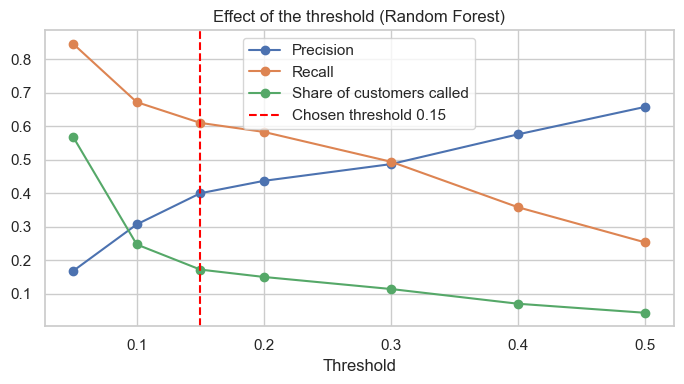

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thr["Threshold"], thr["Precision"], marker="o", label="Precision")
ax.plot(thr["Threshold"], thr["Recall"], marker="o", label="Recall")
ax.plot(thr["Threshold"], thr["% called"] / 100, marker="o", label="Share of customers called")
ax.axvline(best_t, color="red", ls="--", label=f"Chosen threshold {best_t}")
ax.set(title=f"Effect of the threshold ({best_model})", xlabel="Threshold")
ax.legend(); plt.tight_layout(); plt.savefig("figures/fig6_threshold.png", dpi=150); plt.show()

### 5.1 Result on the test set

Threshold 0.5: call 4.2% of customers, precision 0.655, recall 0.244
Threshold 0.15: call 17.2% of customers, precision 0.418, recall 0.637


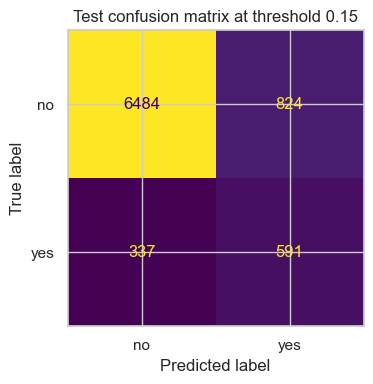

In [18]:
p_test = test_prob[best_model]
for t in [0.5, best_t]:
    called = p_test >= t
    print(f"Threshold {t}: call {called.mean():.1%} of customers, "
          f"precision {precision_score(y_test, called):.3f}, recall {recall_score(y_test, called):.3f}")

pred = (p_test >= best_t).astype(int)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["no", "yes"]).plot(ax=ax, colorbar=False)
ax.set_title(f"Test confusion matrix at threshold {best_t}")
plt.tight_layout(); plt.savefig("figures/fig7_confusion.png", dpi=150); plt.show()

**Recommendation.** Use a threshold of **0.15**. On the test set the bank calls 17% of customers and reaches 64% of subscribers. About 42% of calls succeed, compared with 11% if calling at random.

The default threshold of 0.50 calls only 4% of customers. Its calls succeed more often (66%), but it misses three quarters of subscribers.

If a new subscriber is worth more than assumed, the bank should lower the threshold and call more people. If calls cost more, or staff time is limited, it should raise the threshold.

## 6. Conclusions and Limitations

**Conclusions**
- Recommended model is **Random Forest**, with Logistic Regression as a simpler alternative.
- All models beat the majority baseline.
- Recommended threshold is **0.15**, based on the example costs.

**Limitations**
- The cost figures are assumptions. The bank should redo the threshold table with its real costs.
- Results on later data are weaker, so the model should be retrained and monitored over time.
- The data only covers customers the bank chose to call.
- The patterns found are predictive, not causal.